In [ ]:
import yfinance as yf
import datetime as dt
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import numpy as np


In [ ]:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
# assets = ['BTC-USD', 'GC=F', 'JPM', 'BAC', 'WFC', 'C', 'GS', 'MS', 'PNC', 'USB','AAPL', 'MSFT', 'GOOGL', 'AMZN', 'NVDA', 'META', 'TSLA', 'INTC', 'CSCO','JNJ', 'PFE', 'UNH', 'MRK', 'LLY', 'ABBV', 'GILD', 'TMO', 'MRNA','AMT', 'PLD', 'CCI', 'SPG', 'PSA', 'EQIX', 'O', 'VNO', 'AVB','SCHW', 'BLK', 'GS', 'MS', 'RJF', 'TROW', 'AMP', 'IBKR']
# assets = ['GILD','MRK']
assets = ['UUP','GC=F','KC=F','ZW=F','ZS=F','SB=F','HG=F','JPM', 'BAC','TSLA','AAPL','KO','USDJPY=X','VNQ','REET','IEF','BTC-USD','ETH-USD','GBPUSD=X','FTSM']

start = "2015-1-1"
end = "2019-12-31"
data = yf.download(assets, start = start, end = end)['Close'].ffill().dropna()

data






[*********************100%***********************]  20 of 20 completed


Ticker,AAPL,BAC,BTC-USD,ETH-USD,FTSM,GBPUSD=X,GC=F,HG=F,IEF,JPM,KC=F,KO,REET,SB=F,TSLA,USDJPY=X,UUP,VNQ,ZS=F,ZW=F
Date,,,,,,,,,,,,,,,,,,,,
2017-11-09,41.227737,22.364168,7143.580078,320.884003,50.405182,1.311303,1285.599976,3.0800,91.602936,79.687851,126.400002,36.791870,19.602190,14.88,20.199333,113.927002,21.218157,63.876068,975.25,429.00
2017-11-10,41.091312,22.381046,6618.140137,299.252991,50.405182,1.314440,1272.400024,3.0695,91.137947,79.589928,127.550003,37.038586,19.587042,14.96,20.199333,113.375000,21.200882,63.943859,977.25,431.50
2017-11-11,41.091312,22.381046,6357.600098,314.681000,50.405182,1.314440,1272.400024,3.0695,91.137947,79.589928,127.550003,37.038586,19.587042,14.96,20.199333,113.375000,21.200882,63.943859,977.25,431.50
2017-11-12,41.091312,22.381046,5950.069824,307.907990,50.405182,1.314440,1272.400024,3.0695,91.137947,79.589928,127.550003,37.038586,19.587042,14.96,20.199333,113.375000,21.200882,63.943859,977.25,431.50
2017-11-13,40.926632,22.288185,6559.490234,316.716003,50.413555,1.312026,1277.300049,3.1115,91.094879,79.875572,127.599998,37.181850,19.624914,15.13,21.026667,113.685997,21.218157,64.267578,963.50,424.25
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2019-12-26,70.265671,31.366941,7238.966797,126.361221,52.865597,1.297353,1509.300049,2.8645,99.769531,119.712181,127.300003,47.120434,23.272476,13.44,28.729334,109.369003,23.376276,75.995071,937.75,549.00
2019-12-27,70.238983,31.216822,7290.088379,127.214607,52.883217,1.300221,1513.800049,2.8365,99.913956,119.798271,132.500000,47.403046,23.298044,13.54,28.691999,109.542000,23.260376,76.235275,929.50,556.25
2019-12-28,70.238983,31.216822,7317.990234,128.322708,52.883217,1.300221,1513.800049,2.8365,99.913956,119.798271,132.500000,47.403046,23.298044,13.54,28.691999,109.542000,23.260376,76.235275,929.50,556.25


In [ ]:
long_period = 20
short_period = 5

In [ ]:
#daily return to join later
def trade(data):
  df = pd.DataFrame()
  df['Close'] = data
  df['MA_long'] = df['Close'].rolling(window=long_period).mean()
  df['MA_short'] = df['Close'].rolling(window=short_period).mean()
  df['signal'] = np.where(df['MA_short'] > df['MA_long'], 1, np.where(df['MA_short'] < df['MA_long'], -1, 0))
  df['return'] = data.pct_change()
  df['strategy'] = df['signal'].shift(1) * df['return']
  df.dropna(inplace=True)
  df['cumret'] = (1 + df['strategy']).cumprod()

  return df['strategy']


In [ ]:
# prompt: RSI trade function

def rsi_trade(data, period=3):
    delta = data.diff()
    gain = delta.where(delta > 0, 0)
    loss = -delta.where(delta < 0, 0)
    avg_gain = gain.rolling(window=period).mean()
    avg_loss = loss.rolling(window=period).mean()
    rs = avg_gain / avg_loss
    rsi = 100 - (100 / (1 + rs))

    # Trading signals based on RSI
    overbought = 90
    oversold = 10
    df = pd.DataFrame()
    df['RSI'] = rsi
    df['signal'] = 0.0
    df['signal'][rsi < oversold] = 1  # Buy signal
    df['signal'][rsi > overbought] = -1  # Sell signal
    df['return'] = data.pct_change()
    df['strategy'] = df['signal'].shift(1) * df['return']
    df.dropna(inplace=True)
    df['cumret'] = (1 + df['strategy']).cumprod()
    return df['strategy']

In [ ]:

def bb_trade(data, window=200, std_dev=2):
    df = pd.DataFrame()
    df['Close'] = data
    df['MA'] = df['Close'].rolling(window=window).mean()
    df['StdDev'] = df['Close'].rolling(window=window).std()
    df['Upper'] = df['MA'] + std_dev * df['StdDev']
    df['Lower'] = df['MA'] - std_dev * df['StdDev']

    df['signal'] = 0.0
    df['signal'][df['Close'] < df['Lower']] = 1  # Buy signal
    df['signal'][df['Close'] > df['Upper']] = -1  # Sell signal

    df['return'] = data.pct_change()
    df['strategy'] = df['signal'].shift(1) * df['return']
    df.dropna(inplace=True)
    df['cumret'] = (1 + df['strategy']).cumprod()
    return df['strategy']

0.2069517084644048


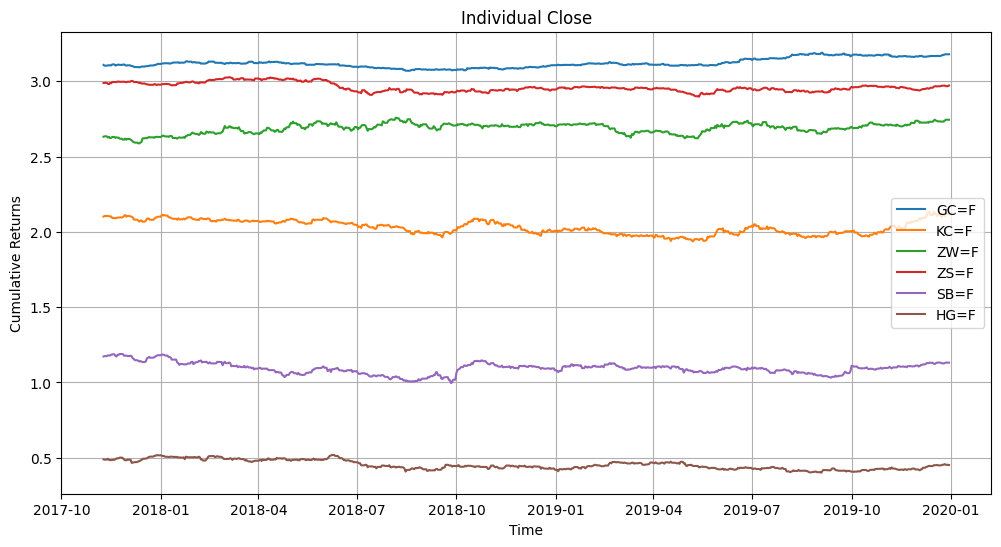

In [ ]:
#comm
commodities = ['GC=F','KC=F','ZW=F','ZS=F','SB=F','HG=F']

weight_comm = 1/len(commodities)
ret_com = pd.DataFrame()
for comm in commodities:
  ret_com[f'{comm}'] = trade(data[comm])

ret_com['return'] = (ret_com*weight_comm).sum(axis=1)
cum_ret = (1+ret_com['return']).cumprod()[-1]-1
print(cum_ret)
# ret_com
plt.figure(figsize=(12,6))
for comm in commodities:
    plt.plot((np.log10(data[f'{comm}'])), label=comm)
plt.xlabel('Time')
plt.ylabel('Cumulative Returns')
plt.title('Individual Close')
plt.legend()
plt.grid(True)
plt.show()




-0.0030173041599592665


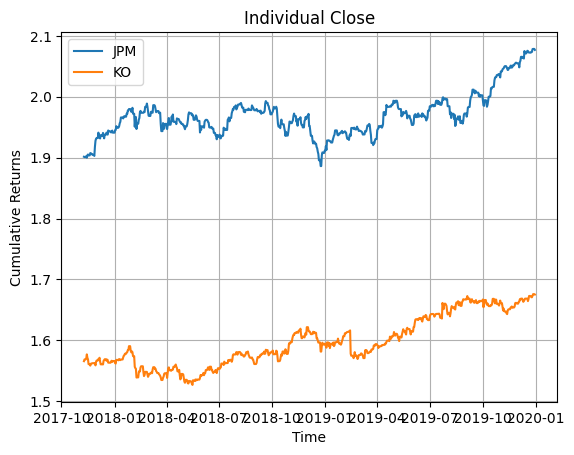

In [ ]:
#stock
stocks = ['JPM','KO']
weight_stock = 1/len(stocks)
ret_stock = pd.DataFrame()
for stock in stocks:
  ret_stock[f'{stock}'] = bb_trade(data[stock])

ret_stock['return'] = (ret_stock*weight_stock).sum(axis=1)
cum_ret = (1+ret_stock['return']).cumprod()[-1]-1
print(cum_ret)
# ret_stock

for stock in stocks:
    plt.plot((np.log10(data[f'{stock}'])), label=stock)
plt.xlabel('Time')
plt.ylabel('Cumulative Returns')
plt.title('Individual Close')
plt.legend()
plt.grid(True)
plt.show()



-0.10961350645899903


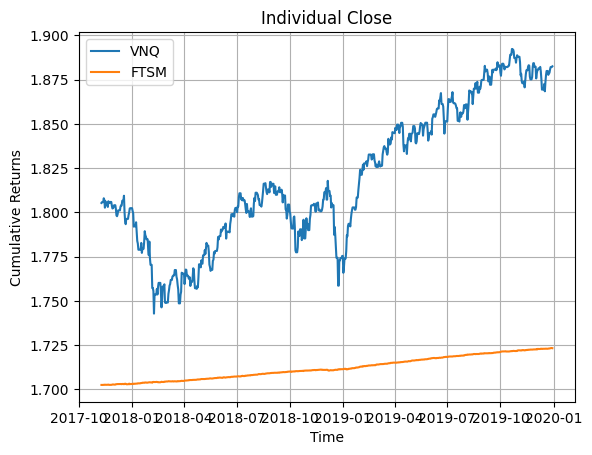

In [ ]:
#real estate
real_estate = ['VNQ','FTSM']
weight_re = 1/len(real_estate)
ret_re = pd.DataFrame()
for re in real_estate:
  ret_re[f'{re}'] = rsi_trade(data[re])

ret_re['return'] = (ret_re*weight_re).sum(axis=1)
cum_ret = (1+ret_re['return']).cumprod()[-1]-1
print(cum_ret)
# ret_stock

for re in real_estate:
    plt.plot((np.log10(data[f'{re}'])), label=re)
plt.xlabel('Time')
plt.ylabel('Cumulative Returns')
plt.title('Individual Close')
plt.legend()
plt.grid(True)
plt.show()

0.786210619671307


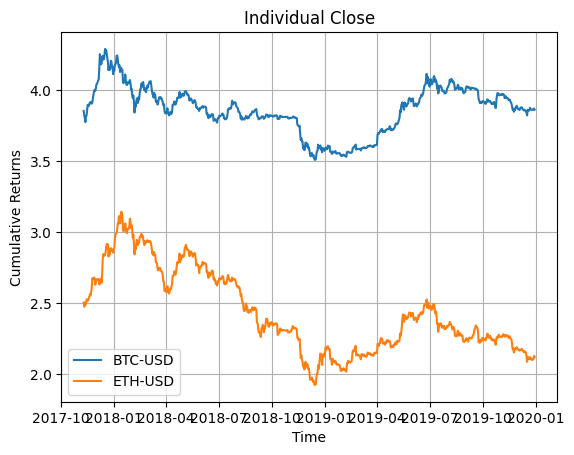

In [ ]:
#crypto
coins = ['BTC-USD','ETH-USD']
weight_coin = 1/len(coins)
ret_coin = pd.DataFrame()
for coin in coins:
  ret_coin[f'{coin}'] = trade(data[coin])

ret_coin['return'] = (ret_coin*weight_coin).sum(axis=1)
cum_ret = (1+ret_coin['return']).cumprod()[-1]-1
print(cum_ret)
# ret_stock

for coin in coins:
    plt.plot((np.log10(data[f'{coin}'])), label=coin)
plt.xlabel('Time')
plt.ylabel('Cumulative Returns')
plt.title('Individual Close')
plt.legend()
plt.grid(True)
plt.show()

-0.03914671356003652


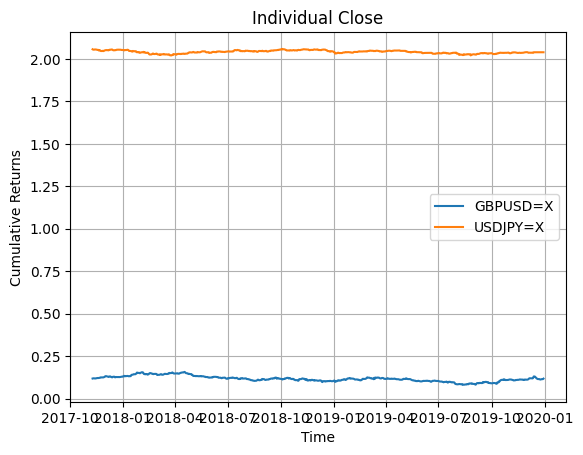

In [ ]:
#currencies
currencies = ['GBPUSD=X','USDJPY=X']
weight_curr = 1/len(currencies)
ret_curr = pd.DataFrame()
for curr in currencies:
  ret_curr[f'{curr}'] = rsi_trade(data[curr])

ret_curr['return'] = (ret_curr*weight_curr).sum(axis=1)

cum_ret = (1+ret_curr['return']).cumprod()[-1]-1
print(cum_ret)
# ret_stock

for curr in currencies:
    plt.plot((np.log10(data[f'{curr}'])), label=curr)
plt.xlabel('Time')
plt.ylabel('Cumulative Returns')
plt.title('Individual Close')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
ret_pot= pd.DataFrame()
ret_pot['comm'] = ret_com['return']
ret_pot['stock'] = ret_stock['return']
ret_pot['re'] = ret_re['return']
ret_pot['coin'] = ret_coin['return']
ret_pot['curr'] = ret_curr['return']
weight = [0.2,0.2,0.2,0.1,0.2]
ret_pot['return'] = (ret_pot*weight).sum(axis=1)
sharpe = (ret_pot['return'].mean()/ret_pot['return'].std())*np.sqrt(252)
print(f'Sharpe: {sharpe}')
cum_ret = (1+ret_pot['return']).cumprod()[-1]-1
print(f'Return {cum_ret}')
#

Sharpe: 0.47040558458592197
Return 0.09043433251242972


           comm     stock        re      coin      curr
comm   1.000000  0.001400 -0.034898  0.015408  0.050660
stock  0.001400  1.000000  0.180649  0.045157  0.088145
re    -0.034898  0.180649  1.000000 -0.014559 -0.024575
coin   0.015408  0.045157 -0.014559  1.000000 -0.003400
curr   0.050660  0.088145 -0.024575 -0.003400  1.000000


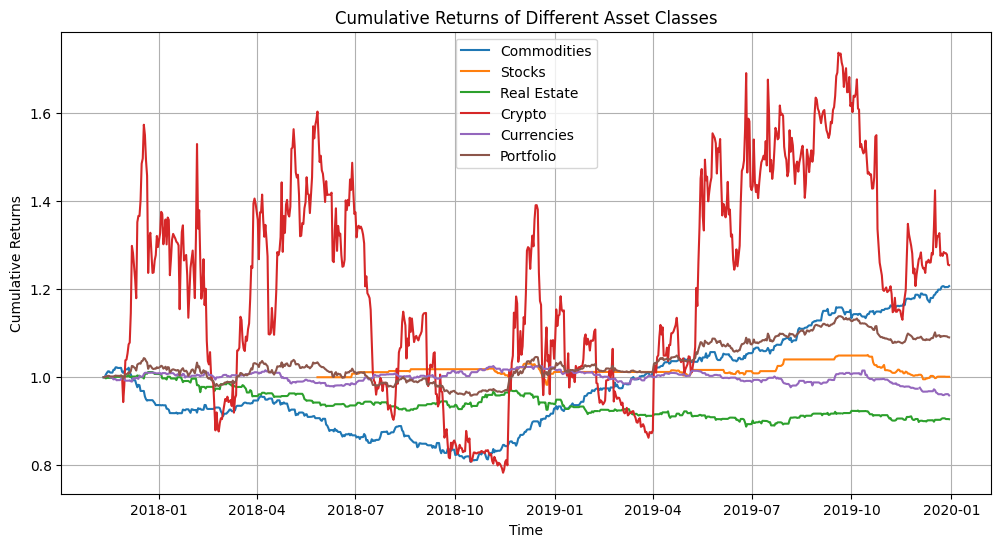

In [ ]:

correlation_matrix = ret_pot[['comm', 'stock', 're', 'coin', 'curr']].corr()
print(correlation_matrix)

plt.figure(figsize=(12, 6))
plt.plot((1 + ret_pot['comm']).cumprod(), label='Commodities')
plt.plot((1 + ret_pot['stock']).cumprod(), label='Stocks')
plt.plot((1 + ret_pot['re']).cumprod(), label='Real Estate')
plt.plot((1 + ret_pot['coin']).cumprod(), label='Crypto')
plt.plot((1 + ret_pot['curr']).cumprod(), label='Currencies')
plt.plot((1 + ret_pot['return']).cumprod(), label='Portfolio')

plt.xlabel('Time')
plt.ylabel('Cumulative Returns')
plt.title('Cumulative Returns of Different Asset Classes')
plt.legend()
plt.grid(True)
plt.show()